# 08 — XGBoost

Gradient boosting with the **same information** as the linear model, to measure what non-linearity alone is worth.

- **Input:** dataset (05) and naive forecasts (06)
- **Output:** `data/processed/xgb_validation_forecasts.parquet`, `results/08_xgboost_*`
- **Chosen model:** `xgb_single` — one model with `local_hour` as a feature (better and 15–20× faster than 24 hourly models); validation MAE 9.13 ± 0.02 over 5 seeds.
- **Key findings:** hyperparameters tuned on an inner year with the same walk-forward protocol as the evaluation; rolling windows hurt trees. Gain over the linear model: −6% on validation — and none on the test year (see 10).

In [1]:
# --- Make src/ importable and reload it automatically when it changes ---------
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import forecasting as fc

TARGET = fc.TARGET

# --- Load dataset and naive forecasts ------------------------------------------
dataset = pd.read_parquet(fc.PROCESSED / "dataset_hourly_2021_2025q3.parquet")
naive = pd.read_parquet(fc.PROCESSED / "naive_forecasts_2021_2025q3.parquet")

NAIVE_COLUMNS = ["naive_d1", "naive_d7", "naive_mean7", "naive_epf"]
dataset = dataset.merge(naive[["ts_utc"] + NAIVE_COLUMNS], on="ts_utc",
                        how="left", validate="one_to_one")

# Split, period and calendar columns always come from src/: one single definition
dataset = fc.add_split_columns(dataset)
dataset = fc.add_calendar_features(dataset)

# --- Same engineered feature as linear_v2/v3 -----------------------------------
# Residual load in GW, so the scale matches the one used in 07_linear
dataset["gas_x_residual_load"] = (
    dataset["gas_price_d1_eur_mwh"] * dataset["residual_load_mw"] / 1000
)

# Exactly the information set of linear_v3 (day of week is added in each design)
FEATURES_V3 = [
    "naive_d1",
    "naive_d7",
    "residual_load_mw",
    "gas_price_d1_eur_mwh",
    "is_holiday",
    "gas_x_residual_load",
    "yesterday_holiday",
]

# --- Linear validation forecasts saved by 07_linear ------------------------------
linear = pd.read_parquet(fc.PROCESSED / "linear_validation_forecasts.parquet")
LINEAR_REFERENCE = ["linear_v3", "linear_v3_roll365", "linear_v3_avg"]
dataset = dataset.merge(linear[["ts_utc"] + LINEAR_REFERENCE], on="ts_utc",
                        how="left", validate="one_to_one")

# --- Checks ----------------------------------------------------------------------
assert len(dataset) == 41615
is_validation = dataset["split"] == "validation"
assert dataset.loc[dataset["split"] != "train", NAIVE_COLUMNS].notna().all().all()
# Linear forecasts must cover the validation year exactly, nothing more
assert dataset.loc[is_validation, LINEAR_REFERENCE].notna().all().all()
assert dataset.loc[~is_validation, LINEAR_REFERENCE].isna().all().all()

print(dataset["split"].value_counts().to_string())

split
train         24071
validation     8784
test           8760


In [2]:
# --- Hourly linear model (same as make_hourly_linear in 07, without asinh) --------
from sklearn.linear_model import LinearRegression


def make_hourly_linear(features: list):
    """Return (fit, predict) for 24 hourly linear regressions on `features`."""

    def design(df: pd.DataFrame) -> pd.DataFrame:
        X = df[features].astype(float)
        # Fixed day-of-week columns (Tuesday..Sunday), Monday = reference category
        for day in range(1, 7):
            X[f"dow_{day}"] = (df["day_of_week"] == day).astype(float)
        return X

    def fit(train: pd.DataFrame) -> dict:
        models = {}
        for hour, rows in train.groupby("local_hour"):
            rows = rows.dropna(subset=features)   # first week of 2021: no naive_d7
            models[hour] = LinearRegression().fit(design(rows), rows[TARGET])
        return models

    def predict(models: dict, day: pd.DataFrame) -> np.ndarray:
        forecast = pd.Series(np.nan, index=day.index)
        for hour, rows in day.groupby("local_hour"):
            forecast.loc[rows.index] = models[hour].predict(design(rows))
        return forecast.to_numpy()

    return fit, predict


fit_v3, predict_v3 = make_hourly_linear(FEATURES_V3)

# --- Regression check: daily refit must reproduce linear_v3 from 07 ---------------
start = time.perf_counter()
check_v3 = fc.walk_forward(dataset, fit_v3, predict_v3, split="validation")
max_diff = (check_v3[is_validation] - dataset.loc[is_validation, "linear_v3"]).abs().max()
assert max_diff < 1e-6, f"linear_v3 not reproduced (max diff {max_diff})"
print(f"linear_v3 reproduced (max diff {max_diff:.1e}) in {time.perf_counter() - start:.0f} s")

# --- Control: same model, refitted every 30 days ----------------------------------
# XGBoost will be refitted monthly for computing time. Without this control, the
# comparison xgb vs linear_v3 would mix two changes: non-linearity AND refit frequency.
# Note: features (lagged prices, gas, forecasts) are still updated EVERY day;
# only the parameters are up to 30 days old.
REFIT_EVERY_DAYS = 30

start = time.perf_counter()
dataset["linear_v3_refit30"] = fc.walk_forward(
    dataset, fit_v3, predict_v3, split="validation", refit_every_days=REFIT_EVERY_DAYS,
)
print(f"walk-forward done in {time.perf_counter() - start:.0f} s\n")

# --- How much does monthly refitting cost the linear model? -----------------------
results_refit = fc.evaluate(dataset, ["naive_epf", "linear_v3", "linear_v3_refit30"],
                            split="validation")
print(results_refit[results_refit["period"] == "all"]
      .set_index("forecast")[["MAE", "RMSE", "rMAE"]].round(2).to_string())

print()
print(pd.DataFrame([
    fc.diebold_mariano(dataset, "linear_v3_refit30", "linear_v3", split="validation", loss=loss)
    for loss in ["abs", "squared"]
]).drop(columns=["n_days"]).round(4).to_string(index=False))

linear_v3 reproduced (max diff 0.0e+00) in 30 s
walk-forward done in 12 s

                     MAE   RMSE  rMAE
forecast                             
naive_epf          12.30  18.35  1.00
linear_v3           9.66  13.53  0.79
linear_v3_refit30   9.70  13.58  0.79

       forecast_a forecast_b    loss  mean_daily_diff  dm_stat  p_value_b_better
linear_v3_refit30  linear_v3     abs           0.0441   5.8902               0.0
linear_v3_refit30  linear_v3 squared           1.4620   3.9464               0.0


In [3]:
# --- Inner split: hyperparameters are chosen INSIDE the training set -------------
# The validation year stays untouched for the model comparison. The last training
# year becomes a small "inner validation", evaluated with the SAME protocol used
# later on validation: walk-forward with a refit every 30 days.
REFIT_EVERY_DAYS = 30
INNER_START = pd.Timestamp("2022-10-01")

train = dataset.loc[dataset["split"] == "train"].dropna(subset=FEATURES_V3)  # first week: no naive_d7
inner_eval = train.loc[train["local_date"] >= INNER_START]
y_inner = inner_eval[TARGET].to_numpy()


def inner_blocks():
    """Yield (fit_rows, block): every block of 30 days is forecast by a model
    fitted on all training rows strictly before the block starts."""
    days = inner_eval["local_date"].drop_duplicates().sort_values()
    for block_start in days.iloc[::REFIT_EVERY_DAYS]:
        block_end = block_start + pd.Timedelta(days=REFIT_EVERY_DAYS)
        fit_rows = train.loc[train["local_date"] < block_start]
        block = inner_eval.loc[(inner_eval["local_date"] >= block_start)
                               & (inner_eval["local_date"] < block_end)]
        # Leakage guard, same rule as fc.walk_forward
        assert fit_rows["local_date"].max() < block["local_date"].min()
        yield fit_rows, block


print(f"inner eval: {inner_eval['local_date'].min():%Y-%m-%d} -> "
      f"{inner_eval['local_date'].max():%Y-%m-%d}, {len(inner_eval)} hours, "
      f"{len(list(inner_blocks()))} refits")

# --- Reference on the inner year: naive EPF and linear_v3 with the same protocol ---
linear_inner = np.full(len(inner_eval), np.nan)
for fit_rows, block in inner_blocks():
    position = inner_eval.index.get_indexer(block.index)
    linear_inner[position] = predict_v3(fit_v3(fit_rows), block)
assert not np.isnan(linear_inner).any(), "some inner hours were not forecast"

reference_mae = pd.Series({
    "naive_epf": np.abs(y_inner - inner_eval["naive_epf"].to_numpy()).mean(),
    "linear_v3_refit30": np.abs(y_inner - linear_inner).mean(),
})
print(reference_mae.round(2).to_string())

inner eval: 2022-10-01 -> 2023-09-30, 8760 hours, 13 refits
naive_epf            21.62
linear_v3_refit30    16.69


structure  max_depth  best_n_trees  inner_MAE_best  inner_MAE_500  seconds
   hourly          2            75           16.91          16.94    77.63
   hourly          3            75           16.55          16.78   102.11
   hourly          4            75           16.31          16.71   128.51
   single          4           500           16.23          16.23     6.07
   single          6            75           16.11          16.23     8.49
   single          8            75           16.12          16.41    11.39


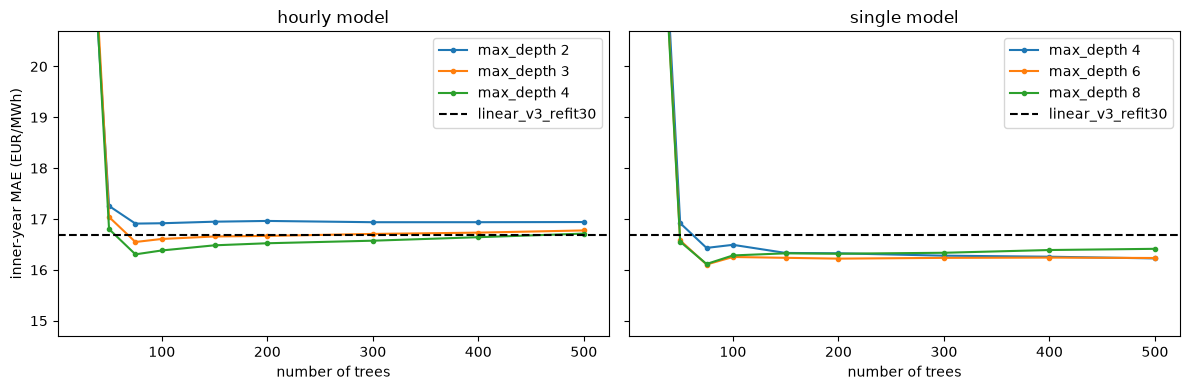

In [4]:
# --- XGBoost grid on the inner year: 24 hourly models vs one single model ----------
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

XGB_FEATURES_HOURLY = FEATURES_V3 + ["day_of_week"]        # integer day: no dummies needed
XGB_FEATURES_SINGLE = XGB_FEATURES_HOURLY + ["local_hour"]  # the tree splits on the hour itself

BASE_PARAMS = dict(
    objective="reg:squarederror",   # same loss as the linear model (mean forecast)
    learning_rate=0.05,
    n_estimators=500,               # upper bound: the best number is read from the curve
    min_child_weight=20,            # at least ~20 hours in every leaf
    subsample=0.8,                  # each tree sees 80% of the rows...
    colsample_bytree=0.8,           # ...and 80% of the features
    tree_method="hist",
    random_state=0,                 # reproducible subsampling
)
# Number of trees at which the forecast is evaluated (no refit needed: see predict)
CHECKPOINTS = [25, 50, 75, 100, 150, 200, 300, 400, 500]

GRID = {
    "hourly": {"features": XGB_FEATURES_HOURLY, "per_hour": True,  "max_depth": [2, 3, 4]},
    "single": {"features": XGB_FEATURES_SINGLE, "per_hour": False, "max_depth": [4, 6, 8]},
}


def inner_mae_curve(features: list, params: dict, per_hour: bool) -> pd.Series:
    """Inner-year MAE as a function of the number of trees.

    A boosted model with 500 trees CONTAINS the models with 25, 50, ... trees:
    predict(iteration_range=(0, k)) uses only the first k trees. One fit per
    refit gives the whole curve.
    """
    predictions = np.full((len(inner_eval), len(CHECKPOINTS)), np.nan)
    for fit_rows, block in inner_blocks():
        groups = fit_rows.groupby("local_hour") if per_hour else [(None, fit_rows)]
        for hour, rows in groups:
            target = block if hour is None else block.loc[block["local_hour"] == hour]
            model = XGBRegressor(**params).fit(rows[features].astype(float), rows[TARGET])
            position = inner_eval.index.get_indexer(target.index)
            X_target = target[features].astype(float)
            for j, n_trees in enumerate(CHECKPOINTS):
                predictions[position, j] = model.predict(X_target, iteration_range=(0, n_trees))
    assert not np.isnan(predictions).any(), "some inner hours were not forecast"
    errors = np.abs(y_inner[:, None] - predictions)
    return pd.Series(errors.mean(axis=0), index=CHECKPOINTS)


curves, rows = {}, []
for structure, spec in GRID.items():
    for depth in spec["max_depth"]:
        start = time.perf_counter()
        curve = inner_mae_curve(spec["features"], {**BASE_PARAMS, "max_depth": depth},
                                spec["per_hour"])
        curves[(structure, depth)] = curve
        rows.append({
            "structure": structure,
            "max_depth": depth,
            "best_n_trees": curve.idxmin(),
            "inner_MAE_best": curve.min(),
            "inner_MAE_500": curve.iloc[-1],
            "seconds": time.perf_counter() - start,
        })

grid_results = pd.DataFrame(rows)
print(grid_results.round(2).to_string(index=False))

# --- Curves: where does adding trees stop helping? ----------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, structure in zip(axes, GRID):
    for (s, depth), curve in curves.items():
        if s == structure:
            ax.plot(curve.index, curve.values, marker="o", markersize=3, label=f"max_depth {depth}")
    ax.axhline(reference_mae["linear_v3_refit30"], color="black", linestyle="--",
               label="linear_v3_refit30")
    ax.set_title(f"{structure} model")
    ax.set_xlabel("number of trees")
    ax.legend()
axes[0].set_ylabel("inner-year MAE (EUR/MWh)")
axes[0].set_ylim(reference_mae["linear_v3_refit30"] - 2, reference_mae["linear_v3_refit30"] + 4)
plt.tight_layout()
plt.show()

In [5]:
# --- XGBoost forecasters for fc.walk_forward: same (fit, predict) interface as linear ---
def make_xgb(features: list, params: dict, per_hour: bool):
    """Return (fit, predict) for XGBoost: 24 hourly models or one single model."""

    def fit(train: pd.DataFrame) -> dict:
        train = train.dropna(subset=features)   # first week of 2021: no naive_d7
        if not per_hour:
            return {"all": XGBRegressor(**params).fit(train[features].astype(float), train[TARGET])}
        return {
            hour: XGBRegressor(**params).fit(rows[features].astype(float), rows[TARGET])
            for hour, rows in train.groupby("local_hour")
        }

    def predict(models: dict, day: pd.DataFrame) -> np.ndarray:
        if not per_hour:
            return models["all"].predict(day[features].astype(float))
        forecast = pd.Series(np.nan, index=day.index)
        for hour, rows in day.groupby("local_hour"):
            forecast.loc[rows.index] = models[hour].predict(rows[features].astype(float))
        return forecast.to_numpy()

    return fit, predict


# --- Frozen configurations, chosen on the inner year (training set only) ----------------
XGB_CONFIGS = {
    "xgb_hourly": {
        "features": XGB_FEATURES_HOURLY,
        "per_hour": True,
        # n_jobs=1: with ~1,000 rows per model, coordinating threads costs more than it saves
        "params": {**BASE_PARAMS, "max_depth": 4, "n_estimators": 200, "n_jobs": 1},
    },
    "xgb_single": {
        "features": XGB_FEATURES_SINGLE,
        "per_hour": False,
        "params": {**BASE_PARAMS, "max_depth": 6, "n_estimators": 200},
    },
}

# --- Walk-forward on the validation year: expanding window, refit every 30 days ---------
for name, config in XGB_CONFIGS.items():
    fit_xgb, predict_xgb = make_xgb(config["features"], config["params"], config["per_hour"])
    start = time.perf_counter()
    dataset[name] = fc.walk_forward(
        dataset, fit_xgb, predict_xgb, split="validation", refit_every_days=REFIT_EVERY_DAYS,
    )
    print(f"{name}: walk-forward done in {time.perf_counter() - start:.0f} s")

# --- Metrics against the naive and linear references (validation only) ------------------
XGB_VERSIONS = list(XGB_CONFIGS)
results_xgb = fc.evaluate(
    dataset, ["naive_epf", "linear_v3", "linear_v3_refit30"] + XGB_VERSIONS, split="validation",
)
print()
print(results_xgb[results_xgb["period"] == "all"]
      .set_index("forecast")[["MAE", "RMSE", "WAPE_pct", "rMAE"]].round(2).to_string())

# --- Diebold-Mariano: does XGBoost beat the linear model with the same refit? ------------
# DM > 0 and p < 0.05 -> forecast_b is significantly more accurate than forecast_a
COMPARISONS = [
    ("linear_v3_refit30", "xgb_hourly"),   # non-linearity, same structure as linear
    ("linear_v3_refit30", "xgb_single"),   # non-linearity + single model
    ("xgb_hourly", "xgb_single"),          # structure only
]
print()
print(pd.DataFrame([
    fc.diebold_mariano(dataset, a, b, split="validation", loss=loss)
    for a, b in COMPARISONS
    for loss in ["abs", "squared"]
]).drop(columns=["n_days"]).round(4).to_string(index=False))

xgb_hourly: walk-forward done in 13 s
xgb_single: walk-forward done in 4 s

                     MAE   RMSE  WAPE_pct  rMAE
forecast                                       
naive_epf          12.30  18.35     11.43  1.00
linear_v3           9.66  13.53      8.98  0.79
linear_v3_refit30   9.70  13.58      9.02  0.79
xgb_hourly          9.36  13.36      8.70  0.76
xgb_single          9.11  12.94      8.46  0.74

       forecast_a forecast_b    loss  mean_daily_diff  dm_stat  p_value_b_better
linear_v3_refit30 xgb_hourly     abs           0.3426   2.1792            0.0147
linear_v3_refit30 xgb_hourly squared           6.0236   0.9334            0.1753
linear_v3_refit30 xgb_single     abs           0.5990   3.3823            0.0004
linear_v3_refit30 xgb_single squared          16.9859   2.1516            0.0157
       xgb_hourly xgb_single     abs           0.2564   2.7928            0.0026
       xgb_hourly xgb_single squared          10.9624   2.9221            0.0017


In [6]:
# --- Seed check: how much does xgb_single move with the random subsampling? -----------
# subsample and colsample_bytree draw rows and features at random: a different seed
# gives different trees. This measures stability, it does NOT choose anything.
SEEDS = [0, 1, 2, 3, 4]
single = XGB_CONFIGS["xgb_single"]

seed_columns, seed_rows = [], []
start = time.perf_counter()
for seed in SEEDS:
    column = f"xgb_single_seed{seed}"
    params = {**single["params"], "random_state": seed}
    fit_xgb, predict_xgb = make_xgb(single["features"], params, single["per_hour"])
    dataset[column] = fc.walk_forward(
        dataset, fit_xgb, predict_xgb, split="validation", refit_every_days=REFIT_EVERY_DAYS,
    )
    seed_columns.append(column)

    # Is the gain over the linear model significant for EVERY seed?
    dm = fc.diebold_mariano(dataset, "linear_v3_refit30", column, split="validation", loss="abs")
    seed_rows.append({"seed": seed, "dm_abs": dm["dm_stat"], "p_abs": dm["p_value_b_better"]})
print(f"{len(SEEDS)} walk-forwards done in {time.perf_counter() - start:.0f} s")

# Seed 0 is the configuration already run: same seed must give the same forecast
is_validation = dataset["split"] == "validation"
assert np.allclose(dataset.loc[is_validation, "xgb_single_seed0"],
                   dataset.loc[is_validation, "xgb_single"]), "xgb_single is not reproducible"

# --- Metrics per seed, then their spread ----------------------------------------------
metrics_seeds = fc.evaluate(dataset, seed_columns, split="validation")
metrics_seeds = metrics_seeds.loc[metrics_seeds["period"] == "all", ["MAE", "RMSE", "rMAE"]]
per_seed = pd.concat([pd.DataFrame(seed_rows), metrics_seeds.reset_index(drop=True)], axis=1)
print()
print(per_seed.round(4).to_string(index=False))

print("\nspread across seeds:")
print(per_seed[["MAE", "RMSE", "rMAE"]].agg(["mean", "std", "min", "max"]).round(3).to_string())

5 walk-forwards done in 21 s

 seed  dm_abs  p_abs    MAE    RMSE   rMAE
    0  3.3823 0.0004 9.1051 12.9416 0.7405
    1  3.1143 0.0009 9.1436 12.9839 0.7436
    2  3.2403 0.0006 9.1177 12.9487 0.7415
    3  3.2369 0.0006 9.1422 12.9507 0.7435
    4  3.3176 0.0005 9.1267 12.9558 0.7422

spread across seeds:
        MAE    RMSE   rMAE
mean  9.127  12.956  0.742
std   0.016   0.016  0.001
min   9.105  12.942  0.740
max   9.144  12.984  0.744


In [7]:
# --- Modification D for XGBoost: rolling window and window averaging --------------------
# Same frozen xgb_single configuration (seed 0); only the training window changes.
# With window_days=365 the model never sees the gas crisis: trees cannot extrapolate,
# so any price or gas level outside the last year is a risk.
WINDOW_DAYS = 365
fit_single, predict_single = make_xgb(single["features"], single["params"], single["per_hour"])

start = time.perf_counter()
dataset["xgb_single_roll365"] = fc.walk_forward(
    dataset, fit_single, predict_single, split="validation",
    window_days=WINDOW_DAYS, refit_every_days=REFIT_EVERY_DAYS,
)
print(f"xgb_single_roll365: walk-forward done in {time.perf_counter() - start:.0f} s")

# Linear control with the SAME protocol: rolling 365 days, refit every 30 days
start = time.perf_counter()
dataset["linear_v3_roll365_refit30"] = fc.walk_forward(
    dataset, fit_v3, predict_v3, split="validation",
    window_days=WINDOW_DAYS, refit_every_days=REFIT_EVERY_DAYS,
)
print(f"linear_v3_roll365_refit30: walk-forward done in {time.perf_counter() - start:.0f} s")

# Calibration window averaging: mean of the expanding and the rolling forecasts
dataset["xgb_single_avg"] = dataset[["xgb_single", "xgb_single_roll365"]].mean(axis=1)
dataset["linear_v3_avg_refit30"] = (
    dataset[["linear_v3_refit30", "linear_v3_roll365_refit30"]].mean(axis=1)
)

# --- Metrics ---------------------------------------------------------------------------------
WINDOW_CANDIDATES = [
    "linear_v3_refit30", "linear_v3_roll365_refit30", "linear_v3_avg_refit30",
    "xgb_single", "xgb_single_roll365", "xgb_single_avg",
]
results_windows = fc.evaluate(dataset, ["naive_epf"] + WINDOW_CANDIDATES, split="validation")
print()
print(results_windows[results_windows["period"] == "all"]
      .set_index("forecast")[["MAE", "RMSE", "rMAE"]].round(2).to_string())

# --- Diebold-Mariano ---------------------------------------------------------------------------
WINDOW_COMPARISONS = [
    ("xgb_single", "xgb_single_roll365"),          # rolling alone
    ("xgb_single", "xgb_single_avg"),              # does averaging help trees too?
    ("linear_v3_avg_refit30", "xgb_single_avg"),   # best linear vs best XGBoost, same protocol
]
print()
print(pd.DataFrame([
    fc.diebold_mariano(dataset, a, b, split="validation", loss=loss)
    for a, b in WINDOW_COMPARISONS
    for loss in ["abs", "squared"]
]).drop(columns=["n_days"]).round(4).to_string(index=False))

xgb_single_roll365: walk-forward done in 4 s
linear_v3_roll365_refit30: walk-forward done in 12 s

                             MAE   RMSE  rMAE
forecast                                     
naive_epf                  12.30  18.35  1.00
linear_v3_refit30           9.70  13.58  0.79
linear_v3_roll365_refit30   9.71  13.43  0.79
linear_v3_avg_refit30       9.42  13.20  0.77
xgb_single                  9.11  12.94  0.74
xgb_single_roll365          9.71  13.56  0.79
xgb_single_avg              9.15  12.97  0.74

           forecast_a         forecast_b    loss  mean_daily_diff  dm_stat  p_value_b_better
           xgb_single xgb_single_roll365     abs          -0.6028  -4.6448            1.0000
           xgb_single xgb_single_roll365 squared         -16.2322  -3.6365            0.9999
           xgb_single     xgb_single_avg     abs          -0.0461  -0.6856            0.7535
           xgb_single     xgb_single_avg squared          -0.6620  -0.3013            0.6184
linear_v3_avg_refit30

In [8]:
# --- Best linear vs chosen XGBoost, same refit protocol -----------------------------
print(pd.DataFrame([
    fc.diebold_mariano(dataset, "linear_v3_avg_refit30", "xgb_single", split="validation", loss=loss)
    for loss in ["abs", "squared"]
]).drop(columns=["n_days"]).round(4).to_string(index=False))

           forecast_a forecast_b    loss  mean_daily_diff  dm_stat  p_value_b_better
linear_v3_avg_refit30 xgb_single     abs           0.3101   2.0722            0.0191
linear_v3_avg_refit30 xgb_single squared           6.6987   1.0530            0.1462


In [9]:
# --- Save: validation forecasts, metrics, tests and the frozen configuration --------------
import json

FINAL_XGB = "xgb_single"   # chosen on validation; the test set is evaluated later, once

LINEAR_CONTROLS = ["linear_v3_refit30", "linear_v3_roll365_refit30", "linear_v3_avg_refit30"]
XGB_VERSIONS = ["xgb_hourly", "xgb_single", "xgb_single_roll365", "xgb_single_avg"] + seed_columns

fc.RESULTS.mkdir(exist_ok=True)

# Validation forecasts: the final comparison notebook loads them instead of re-running
validation = dataset.loc[dataset["split"] == "validation"]
KEEP = ["ts_utc", "ts_local", "local_date", "local_hour", "period", "split", TARGET]
forecasts_out = validation[KEEP + NAIVE_COLUMNS + LINEAR_CONTROLS + XGB_VERSIONS].reset_index(drop=True)

forecasts_path = fc.PROCESSED / "xgb_validation_forecasts.parquet"
forecasts_out.to_parquet(forecasts_path, index=False)
pd.testing.assert_frame_equal(pd.read_parquet(forecasts_path), forecasts_out)

# Metrics of every version, linear controls included
metrics = fc.evaluate(dataset, NAIVE_COLUMNS + LINEAR_CONTROLS + XGB_VERSIONS, split="validation")
metrics.to_csv(fc.RESULTS / "08_xgboost_validation_metrics.csv", index=False)

# Each step tested against the model it modified: the path that led to the final choice
STEPS = [
    ("linear_v3", "linear_v3_refit30"),              # cost of refitting every 30 days (linear)
    ("linear_v3_refit30", "xgb_hourly"),             # non-linearity, same structure
    ("linear_v3_refit30", "xgb_single"),             # non-linearity + single model
    ("xgb_hourly", "xgb_single"),                    # structure only
    ("xgb_single", "xgb_single_roll365"),            # D: rolling window
    ("xgb_single", "xgb_single_avg"),                # D: window averaging
    ("linear_v3_avg_refit30", "xgb_single"),         # best linear vs chosen XGBoost, same refit
]
dm_steps = pd.DataFrame([
    fc.diebold_mariano(dataset, a, b, split="validation", loss=loss)
    for a, b in STEPS
    for loss in ["abs", "squared"]
])
dm_steps.to_csv(fc.RESULTS / "08_xgboost_dm_tests.csv", index=False)

# Robustness of the last comparison: the seed-0 result could be lucky, so repeat
# the test for every seed (no refit needed, the forecasts already exist)
dm_seeds_vs_linear = pd.DataFrame([
    fc.diebold_mariano(dataset, "linear_v3_avg_refit30", column, split="validation", loss=loss)
    for column in seed_columns
    for loss in ["abs", "squared"]
])
dm_seeds_vs_linear.to_csv(fc.RESULTS / "08_xgboost_dm_seeds_vs_linear.csv", index=False)
print(dm_seeds_vs_linear.drop(columns=["forecast_a", "n_days"]).round(4).to_string(index=False))
print()

# Inner-year grid (training set only) and seed stability
grid_results.to_csv(fc.RESULTS / "08_xgboost_inner_grid.csv", index=False)
per_seed.to_csv(fc.RESULTS / "08_xgboost_seeds.csv", index=False)

# Frozen configuration: the final notebook rebuilds exactly this model for the test year
config_out = {
    "name": FINAL_XGB,
    "features": XGB_CONFIGS[FINAL_XGB]["features"],
    "per_hour": XGB_CONFIGS[FINAL_XGB]["per_hour"],
    "params": XGB_CONFIGS[FINAL_XGB]["params"],
    "window_days": None,                      # expanding
    "refit_every_days": REFIT_EVERY_DAYS,
    "seeds_checked": SEEDS,
}
with open(fc.RESULTS / "08_xgboost_config.json", "w") as f:
    json.dump(config_out, f, indent=2)

print(f"saved {forecasts_out.shape} -> {forecasts_path.name}")
for name in ["validation_metrics.csv", "dm_tests.csv", "dm_seeds_vs_linear.csv", "inner_grid.csv", "seeds.csv", "config.json"]:
    print(f"saved -> results/08_xgboost_{name}")
print(f"\nfinal XGBoost model: {FINAL_XGB}")

      forecast_b    loss  mean_daily_diff  dm_stat  p_value_b_better
xgb_single_seed0     abs           0.3101   2.0722            0.0191
xgb_single_seed0 squared           6.6987   1.0530            0.1462
xgb_single_seed1     abs           0.2716   1.7680            0.0385
xgb_single_seed1 squared           5.6062   0.8483            0.1981
xgb_single_seed2     abs           0.2977   1.9295            0.0268
xgb_single_seed2 squared           6.5284   1.0099            0.1563
xgb_single_seed3     abs           0.2731   1.8582            0.0316
xgb_single_seed3 squared           6.4685   1.0429            0.1485
xgb_single_seed4     abs           0.2886   1.9470            0.0258
xgb_single_seed4 squared           6.3363   1.0381            0.1496

saved (8784, 23) -> xgb_validation_forecasts.parquet
saved -> results/08_xgboost_validation_metrics.csv
saved -> results/08_xgboost_dm_tests.csv
saved -> results/08_xgboost_dm_seeds_vs_linear.csv
saved -> results/08_xgboost_inner_grid.csv
s

## Summary

**Protocol.** Same information set as `linear_v3` (lagged prices D-1 and D-7, residual load, gas D-1, gas × residual load, holiday, yesterday holiday, day of week as an integer). Walk-forward over the validation year with an expanding window and a **refit every 30 days**. Hyperparameters were chosen on the last training year (1 Oct 2022 → 30 Sep 2023) with the same walk-forward protocol. **The test set has not been looked at.**

| Version | Change | MAE | RMSE | rMAE | DM (abs) |
|---|---|---|---|---|---|
| `linear_v3_refit30` | control: linear_v3 refitted every 30 days | 9.70 | 13.58 | 0.79 | vs daily refit: −5.89 (tiny but consistent loss) |
| `xgb_hourly` | 24 hourly models, depth 4, 200 trees | 9.36 | 13.36 | 0.76 | vs linear_v3_refit30: 2.18 (p 0.015); squared n.s. |
| **`xgb_single`** | one model with the hour as a feature, depth 6, 200 trees | **9.11** | **12.94** | **0.74** | vs linear_v3_refit30: 3.38 (p 0.0004); vs xgb_hourly: 2.79 (p 0.003) |
| `xgb_single_roll365` | rolling 365-day window | 9.71 | 13.56 | 0.79 | vs xgb_single: −4.64 (significantly worse) |
| `xgb_single_avg` | mean of expanding and rolling | 9.15 | 12.97 | 0.74 | vs xgb_single: −0.69 (no effect) |

**Final choice: `xgb_single`**, MAE **9.13 ± 0.02** across 5 seeds (rMAE 0.74).

**What each step taught:**
- **Refit frequency.** Refitting the linear model every 30 days costs only 0.04 EUR/MWh, yet the DM test is highly significant: statistical significance is not economic relevance.
- **Tune with the evaluation protocol.** A single fit on the inner year gave meaningless curves: a model frozen for 12 months of falling gas prices measures the lack of extrapolation, not the hyperparameters.
- **Number of trees.** With learning rate 0.05 the first ~75 trees only reach the price level; 200 trees were chosen on the plateau, not at the minimum right after the drop.
- **Structure.** 24 hourly models exist because a linear model has one coefficient per feature. Trees split on the hour by themselves: one model with 24× the data is more accurate, more stable and 15–20× faster. The hourly models overfit and do not reduce large errors.
- **Seeds.** Standard deviation across seeds (0.016) is 15–35 times smaller than the differences between models; results are reported as the mean across seeds.
- **Windows.** The rolling window hurts trees while it leaves the linear model unchanged. Likely reason: trees already partition the data by gas level (one sub-model per regime), so forgetting the crisis only removes data. Averaging does not help because the rolling forecast is much worse than the expanding one.
- **Against the best linear.** With the same refit, `xgb_single` beats `linear_v3_avg_refit30` (9.42) on MAE, with borderline significance depending on the seed (p ≈ 0.02–0.06), but not on squared loss. Non-linearity adds −6% over a linear model that already contains the gas × residual load interaction (which alone gave −14%).

**Method note.** Three structural choices were made on validation (structure, rolling window, window averaging). A tree-oriented feature variant (residual-load components without the interaction) was deliberately not tested. In the final comparison, `xgb_single` (monthly refit) faces `linear_v3_avg` (daily refit): a small structural disadvantage to declare.